# P2.19 — Renovation of existing buildings

**Question:** RQ2.8 (what role could renovation of existing buildings play in easing the shortage?). Companion of `p2_16`
(vacant homes against the shortfall) and `p2_05`/`p2_17` (supply).

INE counts buildings licensed (2002-2025) and completed (2011-2025) by type of project, municipality by municipality: new
constructions, and "enlargements, changes and reconstructions", which is every work on an existing building, extensions included.
The unit is the **building**, not the dwelling, and works that need no licence are not counted. So the series show the pace and
the place of rehabilitation work, not the homes it returned to use: how many dwellings a renovated building holds, how many of
them were empty and whether they were let afterwards is not in the data. "Could play" is therefore a question of scale: how
long would today's pace take to touch the excess vacant stock of `p2_16`, under stated numbers of homes per building?

In [1]:
import pandas as pd

from pthousing.analysis import renovation, supply, vacancy
from pthousing.config import PROCESSED
from pthousing.data import interim, typology
from pthousing.viz import charts, style

style.apply_style()
works = interim.read("ine_building_works")
nat = renovation.national(works)
stock = supply.read_stock()
panel = pd.read_parquet(PROCESSED / "panel_municipality_year.parquet")
tab = vacancy.table(stock)
short = vacancy.shortfall(supply.balance(panel, stock))
tab["excess_2021_n"] = vacancy.excess(tab["vacant_2021_n"], tab["dwellings_2021_n"])
tab["excess_2021_per_1000"] = 1000 * tab["excess_2021_n"] / tab["dwellings_2021_n"]
tab["shortfall_per_1000"] = 1000 * short / tab["dwellings_2021_n"]
ty = typology.read().set_index("muni_code")
print(
    f"{nat.index.min()}-{nat.index.max()}; {len(tab)} municipalities; excess vacant homes {tab['excess_2021_n'].sum():,.0f}"
)

2002-2025; 308 municipalities; excess vacant homes 424,681


## Step 1 — The pace nationally
Family-housing buildings licensed and completed, new against works on existing buildings.

In [2]:
windows = {
    "crisis 2002-2014": (2002, 2014),
    "recovery 2014-2025": (2014, 2025),
}
cols = ["licensed_new_n", "licensed_alteration_n", "licensed_total_n"]
ch = renovation.changes(nat, windows, cols).round(0)
style.save_table(nat.round(1).reset_index(), "p2", "renovation_national")
style.save_table(ch.reset_index(names="window"), "p2", "renovation_changes")
nat.loc[[2002, 2008, 2011, 2014, 2017, 2020, 2023, 2025]].round(1)

,licensed_new_n,licensed_alteration_n,licensed_total_n,completed_new_n,completed_alteration_n,completed_total_n,alteration_share_licensed_pct,alteration_share_completed_pct
year,,,,,,,,
2002,41439.0,8413.0,49852.0,NaN,NaN,NaN,16.9,NaN
2008,22639.0,6044.0,28683.0,NaN,NaN,NaN,21.1,NaN
2011,12075.0,5024.0,17099.0,15434.0,4552.0,19986.0,29.4,22.8
2014,5348.0,3112.0,8460.0,5623.0,2585.0,8208.0,36.8,31.5
2017,9218.0,3129.0,12347.0,5633.0,1957.0,7590.0,25.3,25.8
2020,13508.0,3552.0,17060.0,8930.0,2264.0,11194.0,20.8,20.2
2023,14419.0,3599.0,18018.0,10729.0,2326.0,13055.0,20.0,17.8
2025,16279.0,3774.0,20053.0,11125.0,2158.0,13283.0,18.8,16.2


## Step 2 — Where the work is
Completed works per 1,000 dwellings of the 2011 stock over the years between the censuses (2012-2021), by kind of place, and the
share of works on existing buildings among all completed buildings (which does not depend on how many dwellings a building holds).

,municipalities_n,completed_alteration_per_1000,completed_new_per_1000,alteration_share_completed_pct,vacancy_2021_pct,excess_2021_per_1000,shortfall_per_1000
density_class,,,,,,,
intermediate,84,4.6,16.5,20.8,12.5,74.7,23.9
rural,189,6.4,12.5,34.4,14.6,95.6,6.6
urban,35,2.3,8.8,16.0,9.3,43.0,34.3


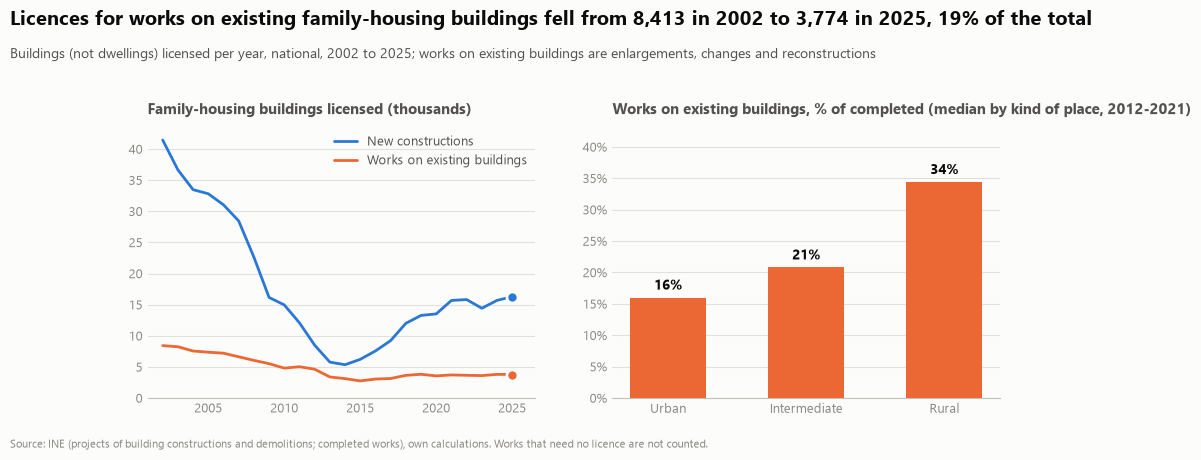

In [3]:
it = renovation.intensity(works, tab)
f = it.join(tab).join(ty[["coast_class", "density_class"]])
measures = [
    "completed_alteration_per_1000",
    "completed_new_per_1000",
    "alteration_share_completed_pct",
    "vacancy_2021_pct",
    "excess_2021_per_1000",
    "shortfall_per_1000",
]
by_density = renovation.group_summary(f, f["density_class"], measures).round(1)
by_coast = renovation.group_summary(f, f["coast_class"], measures).round(1)
style.save_table(by_density.reset_index(), "p2", "renovation_by_density")
style.save_table(by_coast.reset_index(), "p2", "renovation_by_coast")
fig = charts.renovation_works(nat, by_density.loc[["urban", "intermediate", "rural"]])
style.save_fig(fig, "p2", "renovation_works")
by_density

Is renovation where the vacancy is, or where the shortfall is? Spearman correlations across the 308 municipalities.

In [4]:
assoc = renovation.association(
    f,
    "completed_alteration_per_1000",
    [
        "vacancy_2021_pct",
        "vacancy_change_pp",
        "excess_2021_per_1000",
        "shortfall_per_1000",
        "completed_new_per_1000",
    ],
).round(2)
share_assoc = renovation.association(
    f,
    "alteration_share_completed_pct",
    ["vacancy_2021_pct", "excess_2021_per_1000", "shortfall_per_1000"],
).round(2)
style.save_table(assoc.reset_index(), "p2", "renovation_association")
style.save_table(share_assoc.reset_index(), "p2", "renovation_share_association")
print(assoc.to_string())
print(share_assoc.to_string())

                        spearman  p_value    n
against                                       
vacancy_2021_pct            0.05     0.36  308
vacancy_change_pp           0.23     0.00  308
excess_2021_per_1000        0.05     0.36  308
shortfall_per_1000         -0.37     0.00  308
completed_new_per_1000      0.18     0.00  308
                      spearman  p_value    n
against                                     
vacancy_2021_pct          0.19      0.0  308
excess_2021_per_1000      0.19      0.0  308
shortfall_per_1000       -0.37      0.0  308


## Step 3 — How long at this pace?
Excess vacant homes (above a 5% frictional level, `p2_16`) against the buildings of family housing with works on existing buildings
completed a year (average 2015-2024), if each building returned a given number of vacant homes. An upper bound: some of the
homes were occupied, some are not let or sold afterwards. Compared with the simulator's renovation lever (`config/scenarios.yaml`).

In [5]:
pace = nat.loc[2015:2024, "completed_alteration_n"].mean()
excess_n = tab["excess_2021_n"].sum()
years = renovation.years_to_clear(excess_n, pace, [1, 3, 10], [0.25, 0.5, 1.0]).round(0)
style.save_table(years.reset_index(), "p2", "renovation_years_to_clear")
print(
    f"pace {pace:,.0f} completed buildings a year (licensed {nat.loc[2015:2024, 'licensed_alteration_n'].mean():,.0f}); excess {excess_n:,.0f}"
)
years

pace 2,232 completed buildings a year (licensed 3,467); excess 424,681


,25% usable,50% usable,100% usable
dwellings_per_building,,,
1,48.0,95.0,190.0
3,16.0,32.0,63.0
10,5.0,10.0,19.0


## Key numbers

In [6]:
print(
    f"licensed works on existing family-housing buildings: {nat.loc[2002, 'licensed_alteration_n']:,.0f} (2002), {nat.loc[2014, 'licensed_alteration_n']:,.0f} (2014), "
    f"{nat.loc[2025, 'licensed_alteration_n']:,.0f} (2025); new constructions {nat.loc[2002, 'licensed_new_n']:,.0f}, {nat.loc[2014, 'licensed_new_n']:,.0f}, {nat.loc[2025, 'licensed_new_n']:,.0f}"
)
print(
    f"share of works on existing buildings in licences: {nat.loc[2002, 'alteration_share_licensed_pct']:.0f}% (2002), peak {nat['alteration_share_licensed_pct'].max():.0f}% ({nat['alteration_share_licensed_pct'].idxmax()}), "
    f"{nat.loc[2025, 'alteration_share_licensed_pct']:.0f}% (2025); completed {nat.loc[2011, 'alteration_share_completed_pct']:.0f}% (2011), {nat.loc[2025, 'alteration_share_completed_pct']:.0f}% (2025)"
)
print(
    "share of completed works that are on existing buildings, by place (median): "
    + ", ".join(
        f"{k} {by_density.loc[k, 'alteration_share_completed_pct']:.0f}%"
        for k in ("urban", "intermediate", "rural")
    )
)
print(
    f"correlation of renovation per 1,000 dwellings with vacancy {assoc.loc['vacancy_2021_pct', 'spearman']:+.2f}, "
    f"with shortfall per 1,000 {assoc.loc['shortfall_per_1000', 'spearman']:+.2f} (p {assoc.loc['shortfall_per_1000', 'p_value']:.3f}); "
    f"share of works with shortfall {share_assoc.loc['shortfall_per_1000', 'spearman']:+.2f}"
)
print(
    f"years at {pace:,.0f} buildings a year to reach {excess_n:,.0f} excess vacant homes: with one home per building {years.loc[1, '25% usable']:.0f} years for a quarter usable, "
    f"{years.loc[1, '100% usable']:.0f} for all; three per building {years.loc[3, '25% usable']:.0f} and {years.loc[3, '100% usable']:.0f}; ten per building {years.loc[10, '25% usable']:.0f} and {years.loc[10, '100% usable']:.0f}"
)

licensed works on existing family-housing buildings: 8,413 (2002), 3,112 (2014), 3,774 (2025); new constructions 41,439, 5,348, 16,279
share of works on existing buildings in licences: 17% (2002), peak 37% (2013), 19% (2025); completed 23% (2011), 16% (2025)
share of completed works that are on existing buildings, by place (median): urban 16%, intermediate 21%, rural 34%
correlation of renovation per 1,000 dwellings with vacancy +0.05, with shortfall per 1,000 -0.37 (p 0.000); share of works with shortfall -0.37
years at 2,232 buildings a year to reach 424,681 excess vacant homes: with one home per building 48 years for a quarter usable, 190 for all; three per building 16 and 63; ten per building 5 and 19
